# Autoencoders, Explained Simply

**Author:** Amin Pourmohammadi

This notebook teaches one idea: the **autoencoder**.

We will:

1. Understand the idea in plain English.
2. See where autoencoders are used in the real world.
3. Build one by hand in NumPy.
4. Train one in PyTorch on real handwriting.
5. Use it for two real jobs: finding odd examples, and cleaning noisy images.

No heavy math. Short steps. One idea per cell.

## 1. The idea

Think of **packing a suitcase**.

* You have many things to bring.
* The suitcase is small.
* So you must choose what really matters.
* At the other end, you unpack and try to rebuild everything.

An autoencoder does exactly this with data.

| Suitcase | Autoencoder |
|---|---|
| packing | the **encoder** |
| the small suitcase | the **code** (also called the *bottleneck* or *latent space*) |
| unpacking | the **decoder** |
| what you forgot to pack | the **reconstruction error** |

The network is trained to make the unpacked result look like the original.
Nobody tells it *what* to pack. It learns that on its own.

That is why autoencoders need **no labels**.

### Why is this useful?

Because the suitcase is small, the network must learn the **typical pattern** of the data.

Two consequences:

* **Normal data** packs and unpacks well. The error is small.
* **Unusual data** does not fit the learned pattern. The error is large.

So a large reconstruction error is a warning sign.
This is the heart of most real uses.

## 2. Real uses of autoencoders

**Fraud detection in payments.**
Train on normal card transactions.
A fraudulent transaction often packs badly, so its error is high.
Banks and payment firms use this to catch new fraud patterns that have no labels yet.

**Defect detection in factories.**
Train on photos of good parts only.
A scratch or crack cannot be rebuilt well, so it lights up in the error map.
The public MVTec AD benchmark is built around this task.

**Network intrusion detection.**
Train on normal network traffic.
Attacks produce traffic that the model cannot rebuild.

**Denoising medical images.**
Train the network to turn a noisy scan into a clean one.
This is studied for low-dose CT scans, where less radiation means more noise.

**Compressing data for image generators.**
Stable Diffusion does not work on raw pixels.
It first packs each image with an autoencoder (a *variational* autoencoder, VAE).
The image generation happens inside the small suitcase. Then the decoder unpacks it.

**Biology.**
Single-cell RNA data has thousands of genes per cell.
Tools such as scVI (a VAE) pack each cell into a few numbers for plotting and clustering.

**Drug discovery.**
Researchers pack molecules into a small code, search inside it, and unpack new candidate molecules.

**Understanding large language models.**
*Sparse* autoencoders are used to pull out human-readable "features" from inside LLMs.
Anthropic has published research using this method.

## 3. Setup

In [1]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # needed for PyTorch on some Macs

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.datasets import load_digits

In [3]:
np.random.seed(0)
torch.manual_seed(0)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## 4. The data: real handwritten digits

We use the **UCI handwritten digits** dataset.

* 1,797 digits, written by 13 real people (the test half of the UCI dataset).
* Each digit is a tiny 8 × 8 grey image.
* So each digit is 64 numbers.

It ships with scikit-learn, so there is nothing to download.

In [4]:
digits = load_digits()

images = digits.images
labels = digits.target

print("number of images:", len(images))
print("size of one image:", images[0].shape)

number of images: 1797
size of one image: (8, 8)


Let's look at a few.

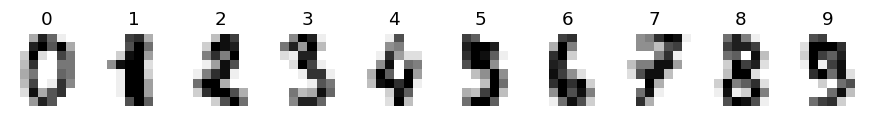

In [5]:
fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))

for i in range(10):
    axes[i].imshow(images[i], cmap="gray_r")
    axes[i].set_title(labels[i])
    axes[i].axis("off")

plt.show()

### Prepare the numbers

Pixel values go from 0 to 16.
Neural networks like small numbers, so we divide by 16.
Now every pixel is between 0 and 1.

We also flatten each 8 × 8 image into one row of 64 numbers.

In [6]:
X = digits.data / 16.0
X = X.astype("float32")

print("shape of X:", X.shape)
print("smallest value:", X.min())
print("largest value:", X.max())

shape of X: (1797, 64)
smallest value: 0.0
largest value: 1.0


## 5. An autoencoder by hand (NumPy)

Before using a library, let's pack and unpack **one** image by hand.

The simplest autoencoder has two steps:

* **Encoder:** multiply the 64 pixels by a weight table. Get 2 numbers. This is the suitcase.
* **Decoder:** multiply those 2 numbers by another weight table. Get 64 numbers back.

The weights start random. So the first attempt will be bad.

In [7]:
W_encode = np.random.normal(0, 0.1, size=(64, 2))
W_decode = np.random.normal(0, 0.1, size=(2, 64))

one_image = X[0]

In [8]:
code_2_numbers = one_image @ W_encode
rebuilt = code_2_numbers @ W_decode

print("the suitcase holds:", code_2_numbers)

the suitcase holds: [0.13364337 0.18519051]


**How bad is it?** We measure the error as the average squared difference per pixel.
This is called the **mean squared error (MSE)**.

In [9]:
difference = one_image - rebuilt
error = np.mean(difference ** 2)

print("reconstruction error:", round(error, 4))

reconstruction error: 0.1913


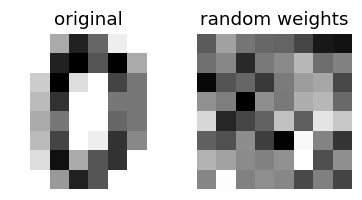

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(4, 2))

axes[0].imshow(one_image.reshape(8, 8), cmap="gray_r")
axes[0].set_title("original")

axes[1].imshow(rebuilt.reshape(8, 8), cmap="gray_r")
axes[1].set_title("random weights")

for ax in axes:
    ax.axis("off")
plt.show()

Random weights pack nothing useful.

**Training** means: nudge the weights, again and again, so the error gets smaller.
Doing this by hand is tedious. PyTorch does it for us.

## 6. A real autoencoder in PyTorch

Our network, layer by layer:

| step | size |
|---|---|
| input image | 64 |
| encoder layer | 32 |
| **the suitcase** | **2** |
| decoder layer | 32 |
| output image | 64 |

Notes:

* `ReLU` lets the network learn curved patterns, not just straight lines.
* `Sigmoid` at the end keeps each output pixel between 0 and 1, like the input.
* We use a suitcase of size **2** so we can draw it later.

In [11]:
def make_autoencoder(code_size):
    encoder = torch.nn.Sequential(
        torch.nn.Linear(64, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, code_size),
    )
    decoder = torch.nn.Sequential(
        torch.nn.Linear(code_size, 32),
        torch.nn.ReLU(),
        torch.nn.Linear(32, 64),
        torch.nn.Sigmoid(),
    )
    return encoder, decoder

### The training loop

Each round (called an **epoch**):

1. Pack and unpack all training images.
2. Measure the error.
3. Ask PyTorch how each weight affects the error (`backward`).
4. Nudge every weight a little (`step`).

The optimizer `Adam` decides how big each nudge is.

In [12]:
def train(encoder, decoder, inputs, targets, epochs=300):
    parameters = list(encoder.parameters()) + list(decoder.parameters())
    optimizer = torch.optim.Adam(parameters, lr=0.01)

    x = torch.tensor(inputs)
    y = torch.tensor(targets)
    history = []

    for epoch in range(epochs):
        rebuilt = decoder(encoder(x))
        loss = torch.mean((rebuilt - y) ** 2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        history.append(loss.item())

    return history

### Hold some digits back

We train on 80% of the digits.
We keep 20% aside to check the model on digits it has never seen.

In [13]:
shuffled = np.random.permutation(len(X))
cut = int(0.8 * len(X))

train_idx = shuffled[:cut]
test_idx = shuffled[cut:]

X_train = X[train_idx]
X_test = X[test_idx]

print("train:", len(X_train), " test:", len(X_test))

train: 1437  test: 360


### Train

Notice we pass `X_train` twice.
The input is the image. The target is **the same image**.
That is the whole trick of an autoencoder.

In [14]:
encoder, decoder = make_autoencoder(code_size=2)
history = train(encoder, decoder, X_train, X_train)

print("error at the start:", round(history[0], 4))
print("error at the end:  ", round(history[-1], 4))

error at the start: 0.1749
error at the end:   0.0415


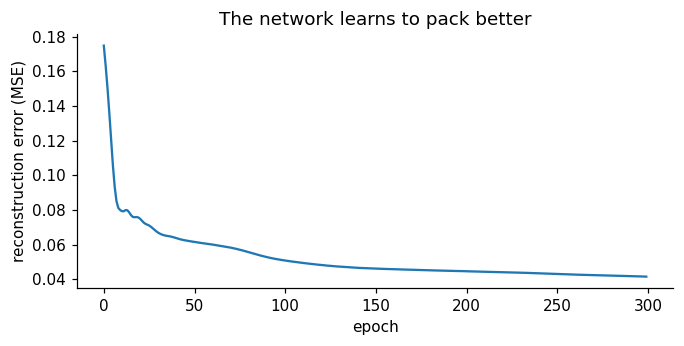

In [15]:
plt.figure(figsize=(7, 3))
plt.plot(history)
plt.xlabel("epoch")
plt.ylabel("reconstruction error (MSE)")
plt.title("The network learns to pack better")
plt.show()

### A helper to pack and unpack

After training we only want answers, not learning.
`torch.no_grad()` tells PyTorch to skip the learning bookkeeping.

In [16]:
def pack(encoder, inputs):
    with torch.no_grad():
        code = encoder(torch.tensor(inputs))
    return code.numpy()


def pack_and_unpack(encoder, decoder, inputs):
    with torch.no_grad():
        rebuilt = decoder(encoder(torch.tensor(inputs)))
    return rebuilt.numpy()

### How good are the unpacked digits?

Top row: real test digits. Bottom row: what came out of a suitcase of just **2 numbers**.

In [17]:
def show_pairs(top, bottom, top_title, bottom_title, n=10):
    fig, axes = plt.subplots(2, n, figsize=(n, 2.4))
    for i in range(n):
        axes[0, i].imshow(top[i].reshape(8, 8), cmap="gray_r")
        axes[1, i].imshow(bottom[i].reshape(8, 8), cmap="gray_r")
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    axes[0, 0].set_title(top_title, loc="left", fontsize=9)
    axes[1, 0].set_title(bottom_title, loc="left", fontsize=9)
    plt.show()

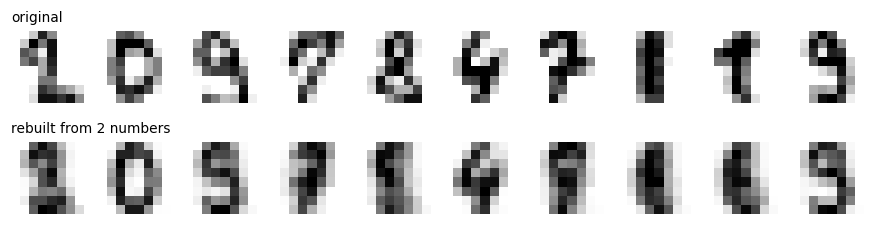

In [18]:
rebuilt_test = pack_and_unpack(encoder, decoder, X_test)
show_pairs(X_test, rebuilt_test, "original", "rebuilt from 2 numbers")

The rebuilt digits are blurry, but most are recognisable.
Not bad for squeezing 64 numbers into 2.

## 7. Looking inside the suitcase

Every digit is now just 2 numbers.
So we can draw every digit as one dot.

The network was **never told** which digit is which.
Yet similar digits end up close together.

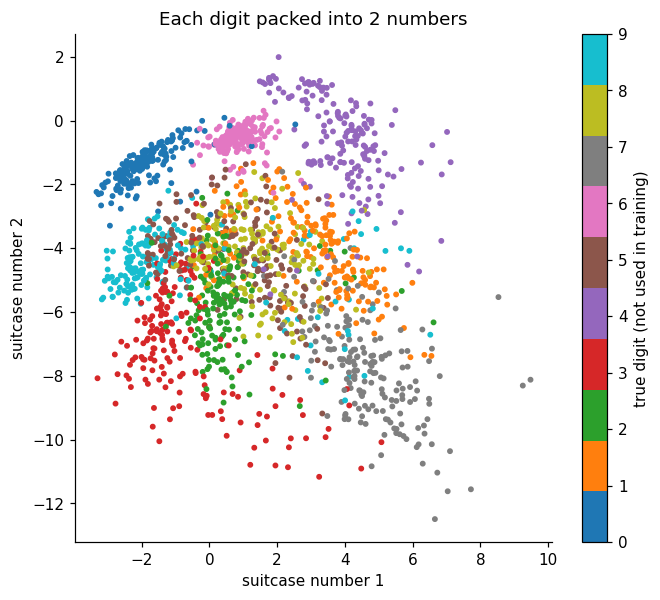

In [19]:
codes = pack(encoder, X)

plt.figure(figsize=(7, 6))
scatter = plt.scatter(codes[:, 0], codes[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(scatter, label="true digit (not used in training)")
plt.xlabel("suitcase number 1")
plt.ylabel("suitcase number 2")
plt.title("Each digit packed into 2 numbers")
plt.show()

Groups form on their own.
This is why autoencoders are used to **compress** and **visualise** big data,
like the single-cell biology example above.

## 8. How big should the suitcase be?

* Too small: we lose detail.
* Bigger: we keep more detail.
* Too big: the network can just copy everything and learns nothing useful.

Let's try a few sizes and check the error on the **test** digits.

In [20]:
code_sizes = [2, 4, 8, 16]
test_errors = []

for size in code_sizes:
    enc, dec = make_autoencoder(code_size=size)
    train(enc, dec, X_train, X_train)

    rebuilt = pack_and_unpack(enc, dec, X_test)
    error = np.mean((rebuilt - X_test) ** 2)
    test_errors.append(error)

    print("suitcase size", size, "-> test error", round(error, 4))

suitcase size 2 -> test error 0.0451


suitcase size 4 -> test error 0.0291


suitcase size 8 -> test error 0.0183


suitcase size 16 -> test error 0.0141


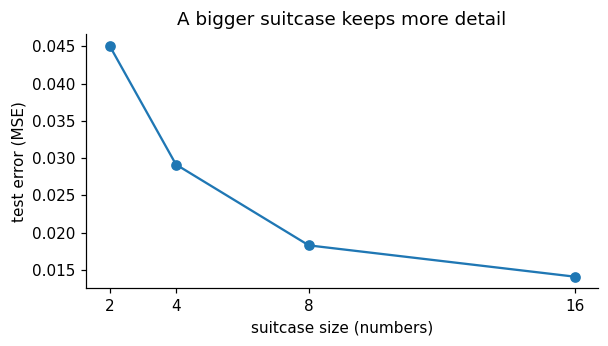

In [21]:
plt.figure(figsize=(6, 3))
plt.plot(code_sizes, test_errors, marker="o")
plt.xticks(code_sizes)
plt.xlabel("suitcase size (numbers)")
plt.ylabel("test error (MSE)")
plt.title("A bigger suitcase keeps more detail")
plt.show()

In practice, you pick the size by the job.
For drawing: 2 or 3. For anomaly detection: small enough to force the network to learn "normal".

## 9. Real use 1: finding the odd one out (anomaly detection)

This is how autoencoders catch fraud and factory defects.

**The experiment:**

* Train only on digits **1 to 9**. The network never sees a **0**.
* Then show it all test digits, zeros included.
* Measure the reconstruction error of each one.

**The expectation:** zeros do not fit what the network learned to pack.
So zeros should have a larger error.

In fraud terms: the digits 1–9 are normal transactions. The zeros are fraud.

In [22]:
is_zero = labels == 0

normal_train_idx = []
for i in train_idx:
    if not is_zero[i]:
        normal_train_idx.append(i)

X_normal_train = X[normal_train_idx]
print("training digits (no zeros):", len(X_normal_train))

training digits (no zeros): 1299


In [23]:
enc_anomaly, dec_anomaly = make_autoencoder(code_size=8)
history = train(enc_anomaly, dec_anomaly, X_normal_train, X_normal_train)

print("final training error:", round(history[-1], 4))

final training error: 0.0173


Now score every test digit.
One error number per digit: the average squared difference over its 64 pixels.

In [24]:
rebuilt = pack_and_unpack(enc_anomaly, dec_anomaly, X_test)
errors = np.mean((rebuilt - X_test) ** 2, axis=1)

test_is_zero = is_zero[test_idx]
print("average error, normal digits:", round(errors[~test_is_zero].mean(), 4))
print("average error, zeros:        ", round(errors[test_is_zero].mean(), 4))

average error, normal digits: 0.0194
average error, zeros:         0.0545


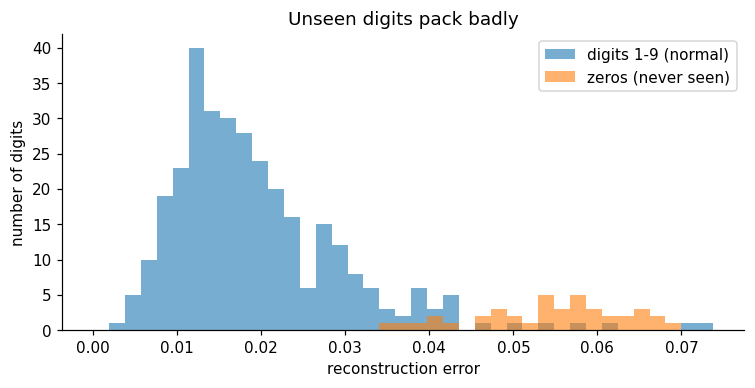

In [25]:
bins = np.linspace(0, errors.max(), 40)

plt.figure(figsize=(8, 3.5))
plt.hist(errors[~test_is_zero], bins=bins, alpha=0.6, label="digits 1-9 (normal)")
plt.hist(errors[test_is_zero], bins=bins, alpha=0.6, label="zeros (never seen)")
plt.xlabel("reconstruction error")
plt.ylabel("number of digits")
plt.title("Unseen digits pack badly")
plt.legend()
plt.show()

### Turn the error into a decision

Pick a cut-off. Anything above it is flagged.

A simple rule: flag the **top 10%** of errors.
How many zeros do we catch?

In [26]:
cutoff = np.percentile(errors, 90)
flagged = errors > cutoff

zeros_caught = np.sum(flagged & test_is_zero)
zeros_total = np.sum(test_is_zero)
false_alarms = np.sum(flagged & ~test_is_zero)

print("cut-off:", round(cutoff, 4))
print("zeros caught:", zeros_caught, "of", zeros_total)
print("normal digits wrongly flagged:", false_alarms)

cut-off: 0.048
zeros caught: 30 of 40
normal digits wrongly flagged: 6


The network never saw a single labelled zero.
Yet it flags most of them.

**This is the key promise for fraud:** it can flag new fraud patterns before anyone has labelled them.

### Which digits look strangest?

The highest-error digits, with their rebuilt versions underneath.

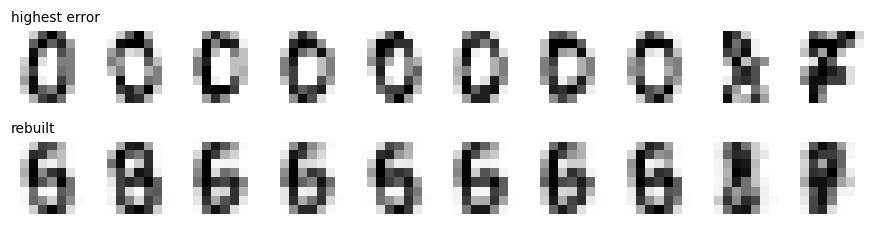

In [27]:
order = np.argsort(errors)  # smallest error first
worst = order[-10:]         # the 10 largest errors

show_pairs(X_test[worst], rebuilt[worst], "highest error", "rebuilt")

The network tries to turn each zero into a digit it knows.
The mismatch is what we measure.

## 10. Real use 2: cleaning noisy images (denoising)

Same network, one small change:

* **Input:** a noisy digit.
* **Target:** the clean digit.

The suitcase is too small to hold the noise.
So the network learns to pack only the digit and leave the noise behind.

This is the idea behind denoising medical scans and old photos.

In [28]:
def add_noise(images, strength=0.3):
    noise = np.random.normal(0, strength, size=images.shape)
    noisy = images + noise
    noisy = np.clip(noisy, 0, 1)
    return noisy.astype("float32")


X_train_noisy = add_noise(X_train)
X_test_noisy = add_noise(X_test)

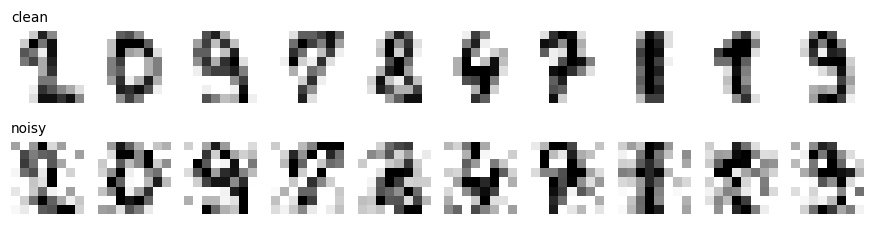

In [29]:
show_pairs(X_test, X_test_noisy, "clean", "noisy")

Train: noisy in, clean out.

In [30]:
enc_denoise, dec_denoise = make_autoencoder(code_size=16)
history = train(enc_denoise, dec_denoise, X_train_noisy, X_train, epochs=500)

print("final training error:", round(history[-1], 4))

final training error: 0.0205


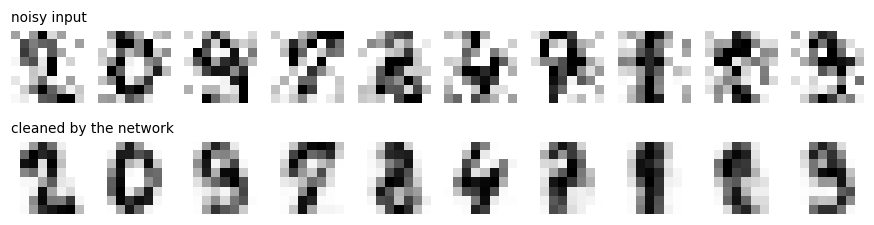

In [31]:
cleaned = pack_and_unpack(enc_denoise, dec_denoise, X_test_noisy)
show_pairs(X_test_noisy, cleaned, "noisy input", "cleaned by the network")

In [32]:
error_before = np.mean((X_test_noisy - X_test) ** 2)
error_after = np.mean((cleaned - X_test) ** 2)

print("difference from clean, before:", round(error_before, 4))
print("difference from clean, after: ", round(error_after, 4))

difference from clean, before: 0.0514
difference from clean, after:  0.0239


The network has never seen these test digits.
It still removes most of the noise.

## 11. Summary

* An autoencoder **packs** data into a small suitcase and **unpacks** it again.
* It learns with **no labels**. The target is the input itself.
* The small suitcase forces it to learn what is **typical**.
* **Reconstruction error** = what didn't survive packing.

What we built:

| job | trick | real-world version |
|---|---|---|
| compression & visualisation | tiny suitcase, plot the code | single-cell biology, Stable Diffusion's VAE |
| anomaly detection | train on normal only, flag high error | fraud, factory defects, network intrusion |
| denoising | noisy in, clean out | medical scans, photo restoration |

**Where to go next**

* **Variational autoencoders (VAE):** the suitcase becomes a smooth space you can sample from, so you can *generate* new data.
* **Convolutional autoencoders:** better for real-size images.
* **Sparse autoencoders:** force most suitcase slots to be empty; used to interpret LLMs.